# 01 · Análisis exploratorio — PlantVillage

**Objetivo:** entender el dataset antes de modelar: tamaños de los splits, balance de clases, aspecto de las imágenes y riesgo de fuga de datos entre train, val y test.

**Datos:** versión de PlantVillage publicada en Hugging Face (`DScomp380/plant_village`): fotos de hojas de varios cultivos, sanas o con una enfermedad, tomadas en condiciones de laboratorio. Cada imagen tiene una etiqueta de clase con el formato `Cultivo___Condición`.

**Preguntas que responde este notebook**
1. ¿Cuántas imágenes y clases hay, y cómo se reparten en train / val / test?
2. ¿Qué tan desbalanceadas están las clases?
3. ¿Cómo se ven las imágenes (tamaño, fondo, variabilidad)?
4. ¿Qué riesgo hay de fuga de datos entre splits?

## 1. Setup

Se importan las librerías y la función de carga de datos de `src/data.py`. El notebook asume la estructura del repositorio (las carpetas `notebooks/` y `src/` dentro de la misma carpeta raíz), por eso se agrega la carpeta superior al `sys.path`.

In [1]:
import os
import sys
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Para poder importar src/ desde notebooks/
sys.path.insert(0, os.path.abspath(".."))
from src.data import load_splits

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_rows", 60)

## 2. Carga de datos

`load_splits()` (definida en `src/data.py`) lee el dataset y lo divide en tres partes:

- **train (70 %):** para entrenar los modelos.
- **val (15 %):** para decidir cuándo detener el entrenamiento y comparar configuraciones.
- **test (15 %):** se reserva y se usa una sola vez, al final, para medir el rendimiento.

El split es **estratificado por clase** (cada clase se reparte en las mismas proporciones) y usa una semilla fija, por lo que es reproducible. El aviso que imprime la celda es esperado: esta versión del dataset no trae un identificador de hoja (`leaf_id`), así que no se pudo agrupar las fotos por hoja física. Las consecuencias de esto se estiman en la sección 6.

In [2]:
train, val, test = load_splits()

sizes = {"train": len(train), "val": len(val), "test": len(test)}
total = sum(sizes.values())
for name, n in sizes.items():
    print(f"{name:>5}: {n:>6} imágenes ({n / total:.1%})")
print(f"total: {total}")

AVISO: el dataset no trae leaf_id; se usa un split estratificado por clase. Puede haber fuga entre imágenes de una misma hoja, por lo que las métricas pueden ser algo optimistas.
train:  38812 imágenes (70.0%)
  val:   8317 imágenes (15.0%)
 test:   8318 imágenes (15.0%)
total: 55447


In [3]:
# Columnas del dataset y sus tipos
train.features

{'image': Image(mode=None, decode=True),
 'label': ClassLabel(names=['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Background_without_leaves', 'Blueberry___healthy', 'Cherry___Powdery_mildew', 'Cherry___healthy', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___Northern_Leaf_Blight', 'Corn___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spi

## 3. Clases

El dataset tiene **39 clases**: 38 combinaciones de cultivo y condición con el formato `Cultivo___Condición` (por ejemplo, `Tomato___Late_blight` o `Apple___healthy`) y una clase adicional, `Background_without_leaves`, con fotos de fondo sin hoja. Armamos un mapa `id → nombre` y una tabla con la cantidad de imágenes de cada clase en cada split.

In [4]:
label_feat = train.features["label"]
if hasattr(label_feat, "names"):
    id2name = dict(enumerate(label_feat.names))
else:
    id2name = {i: str(i) for i in sorted(set(train["label"]))}

n_classes = len(id2name)
print("Cantidad de clases:", n_classes)
list(id2name.values())[:10]

Cantidad de clases: 39


['Apple___Apple_scab',
 'Apple___Black_rot',
 'Apple___Cedar_apple_rust',
 'Apple___healthy',
 'Background_without_leaves',
 'Blueberry___healthy',
 'Cherry___Powdery_mildew',
 'Cherry___healthy',
 'Corn___Cercospora_leaf_spot Gray_leaf_spot',
 'Corn___Common_rust']

In [5]:
def class_counts(ds):
    c = Counter(ds["label"])
    return pd.Series({id2name[k]: v for k, v in c.items()})

df = pd.DataFrame({
    "train": class_counts(train),
    "val": class_counts(val),
    "test": class_counts(test),
}).fillna(0).astype(int)
df["total"] = df.sum(axis=1)
df = df.sort_values("total", ascending=False)
df

,train,val,test,total
Orange___Haunglongbing_(Citrus_greening),3855,826,826,5507
Tomato___Tomato_Yellow_Leaf_Curl_Virus,3750,803,804,5357
Soybean___healthy,3563,763,764,5090
Peach___Bacterial_spot,1608,344,345,2297
Tomato___Bacterial_spot,1489,319,319,2127
Tomato___Late_blight,1336,286,287,1909
Squash___Powdery_mildew,1284,275,276,1835
Tomato___Septoria_leaf_spot,1240,265,266,1771
Tomato___Spider_mites Two-spotted_spider_mite,1173,251,252,1676
Apple___healthy,1152,246,247,1645


### 3.1 Distribución de clases

Cantidad de imágenes por clase. Las clases están **desbalanceadas**: la más grande (`Orange___Haunglongbing_(Citrus_greening)`) tiene 5.507 imágenes y la más chica (`Potato___healthy`) solo 152, una relación de 36,2 a 1. Con este desbalance, la accuracy puede ocultar un mal desempeño en las clases chicas; por eso la métrica principal de los modelos será el **F1 macro**, que da el mismo peso a todas las clases.

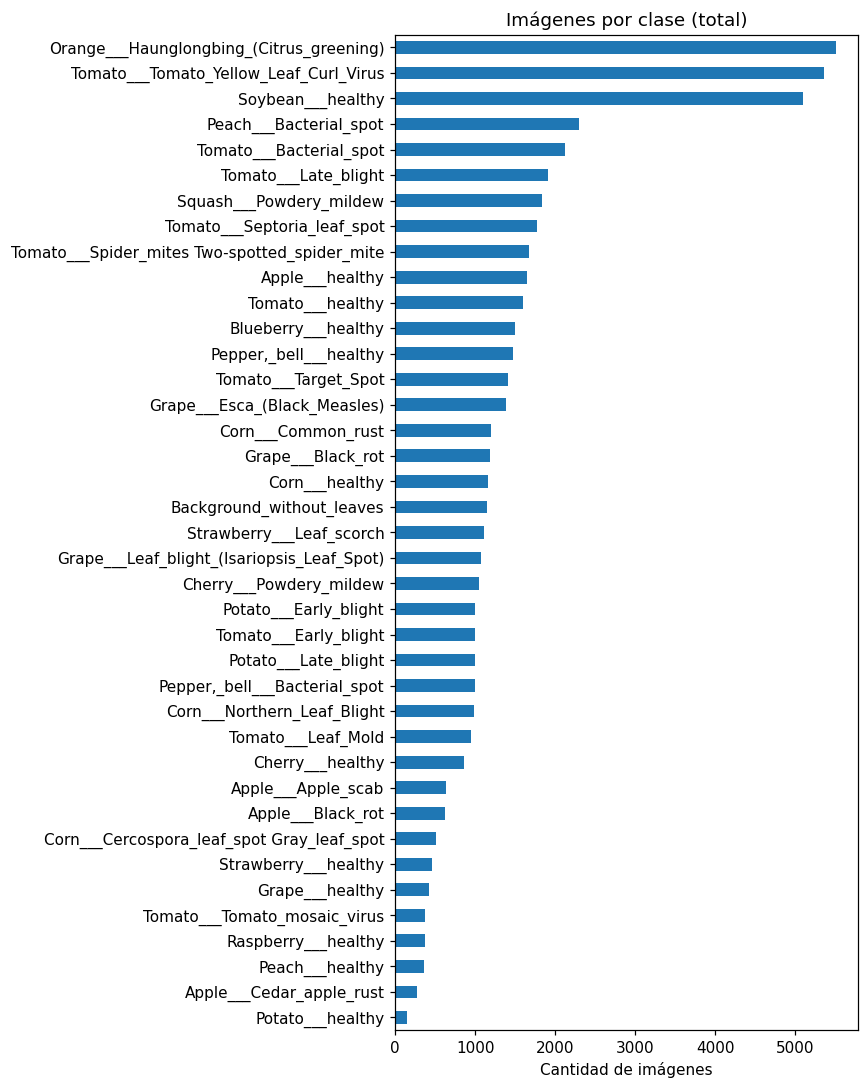

Clase más grande: Orange___Haunglongbing_(Citrus_greening) (5507)
Clase más chica:  Potato___healthy (152)
Ratio de desbalance (max/min): 36.2x


In [6]:
fig, ax = plt.subplots(figsize=(8, 10))
df["total"].sort_values().plot.barh(ax=ax)
ax.set_title("Imágenes por clase (total)")
ax.set_xlabel("Cantidad de imágenes")
plt.tight_layout()
plt.show()

ratio = df["total"].max() / df["total"].min()
print(f"Clase más grande: {df['total'].idxmax()} ({df['total'].max()})")
print(f"Clase más chica:  {df['total'].idxmin()} ({df['total'].min()})")
print(f"Ratio de desbalance (max/min): {ratio:.1f}x")

### 3.2 ¿Se mantienen las proporciones entre splits?

Si una clase pesara muy distinto en train y en test, las métricas serían difíciles de comparar. Como el split es estratificado, la diferencia máxima entre train y test es de 0,01 puntos porcentuales: cada clase tiene prácticamente el mismo peso en los tres conjuntos.

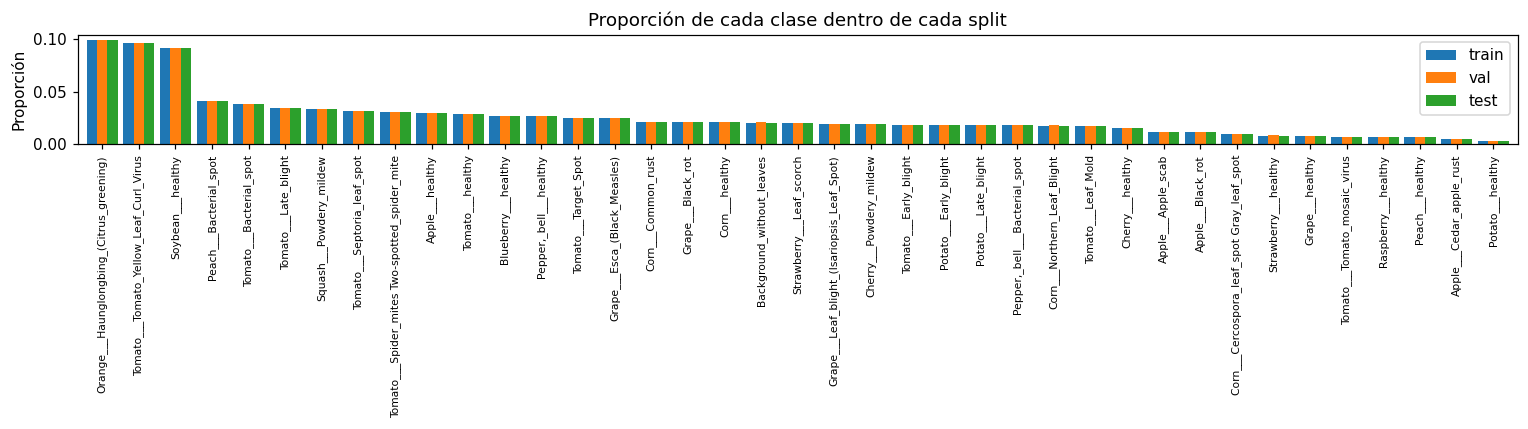

Máxima diferencia train vs test (en puntos porcentuales): 0.01


In [7]:
props = df[["train", "val", "test"]].div(df[["train", "val", "test"]].sum(), axis=1)
props.plot(kind="bar", figsize=(14, 4), width=0.85)
plt.title("Proporción de cada clase dentro de cada split")
plt.ylabel("Proporción")
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

print("Máxima diferencia train vs test (en puntos porcentuales):",
      round((props["train"] - props["test"]).abs().max() * 100, 2))

### 3.3 Cultivo vs. condición

Separamos cada clase en cultivo y condición para ver cuánto pesa cada grupo, y las clasificamos en tres tipos: **sana**, **enferma** y **fondo**. `Background_without_leaves` **no es una hoja**, son fotos de fondo; la marcamos aparte porque mantenerla o no como clase es una decisión de modelado. Hay 39.221 imágenes enfermas, 15.083 sanas y 1.143 de fondo.

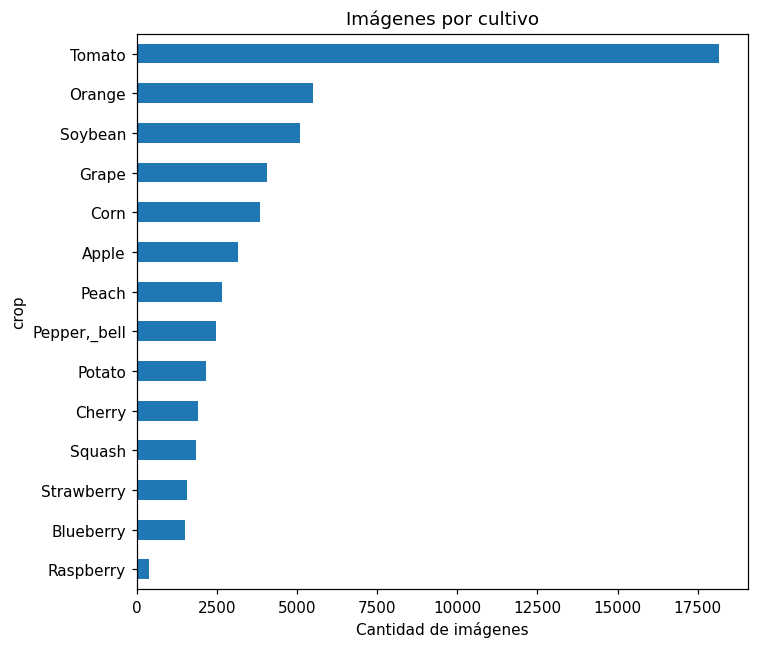

Imágenes por tipo (sana / enferma / fondo):
tipo
enferma    39221
fondo       1143
sana       15083
Name: total, dtype: int64


In [8]:
def split_name(n):
    if "___" in n:
        crop, cond = n.split("___", 1)
    else:
        crop, cond = n, ""
    return crop, cond

parts = [split_name(n) for n in df.index]
df["crop"] = [p[0] for p in parts]
df["condition"] = [p[1] for p in parts]
df["tipo"] = np.where(
    df.index.str.startswith("Background"), "fondo",
    np.where(df["condition"].str.lower().eq("healthy"), "sana", "enferma"),
)

by_crop = df[df["tipo"] != "fondo"].groupby("crop")["total"].sum().sort_values()
by_crop.plot.barh(figsize=(7, 6), title="Imágenes por cultivo")
plt.xlabel("Cantidad de imágenes")
plt.tight_layout()
plt.show()

print("Imágenes por tipo (sana / enferma / fondo):")
print(df.groupby("tipo")["total"].sum())

## 4. Ejemplos visuales (una imagen por clase)

Una foto de cada clase, tomada del conjunto de train, para tener una idea de cómo se ven los datos y de qué tan distintas son entre sí las enfermedades. También sirve para detectar a simple vista problemas como imágenes borrosas o etiquetas dudosas.

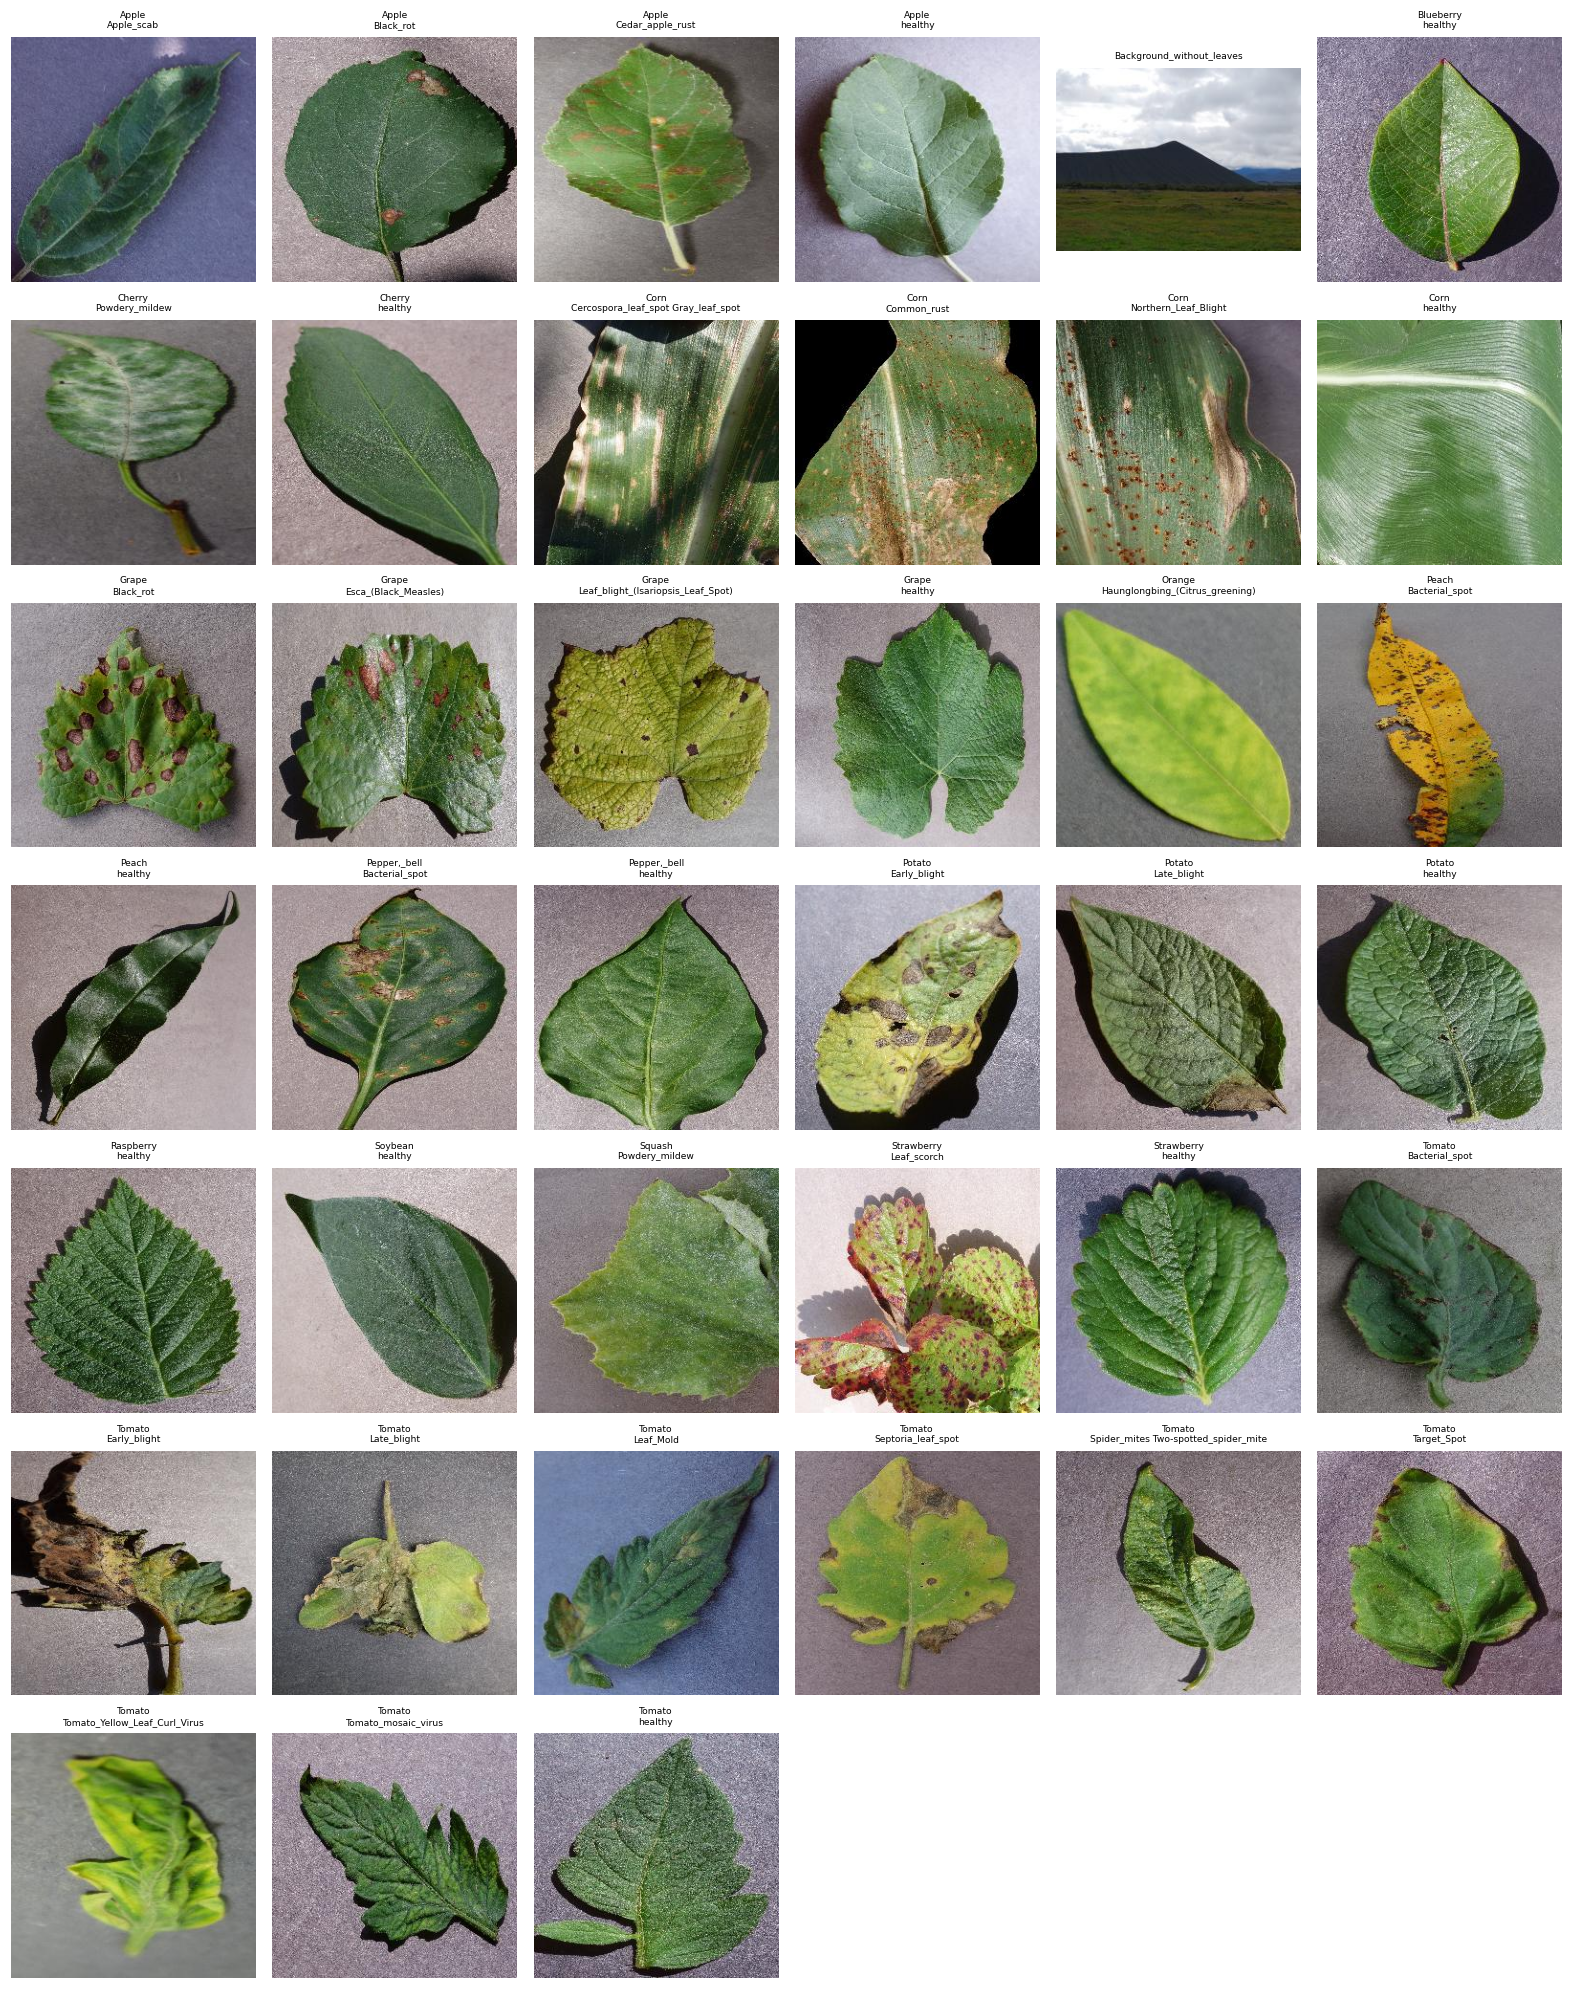

In [9]:
labels_train = np.array(train["label"])
first_idx = {c: int(np.where(labels_train == c)[0][0]) for c in np.unique(labels_train)}

cols = 6
rows = int(np.ceil(len(first_idx) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.4, rows * 2.6))
axes = axes.ravel()

for ax, (c, i) in zip(axes, sorted(first_idx.items())):
    ax.imshow(train[i]["image"])
    ax.set_title(id2name[c].replace("___", "\n"), fontsize=6)
    ax.axis("off")
for ax in axes[len(first_idx):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### 4.1 Variabilidad dentro de una misma clase

Ocho imágenes al azar de la clase más numerosa (`Orange___Haunglongbing_(Citrus_greening)`), para ver cuánto cambian la iluminación, el ángulo y el fondo dentro de una misma clase. Si la variabilidad es baja, al modelo le resulta más fácil aprender, pero también más difícil generalizar a fotos tomadas en otras condiciones, algo que se pone a prueba en el notebook 04.

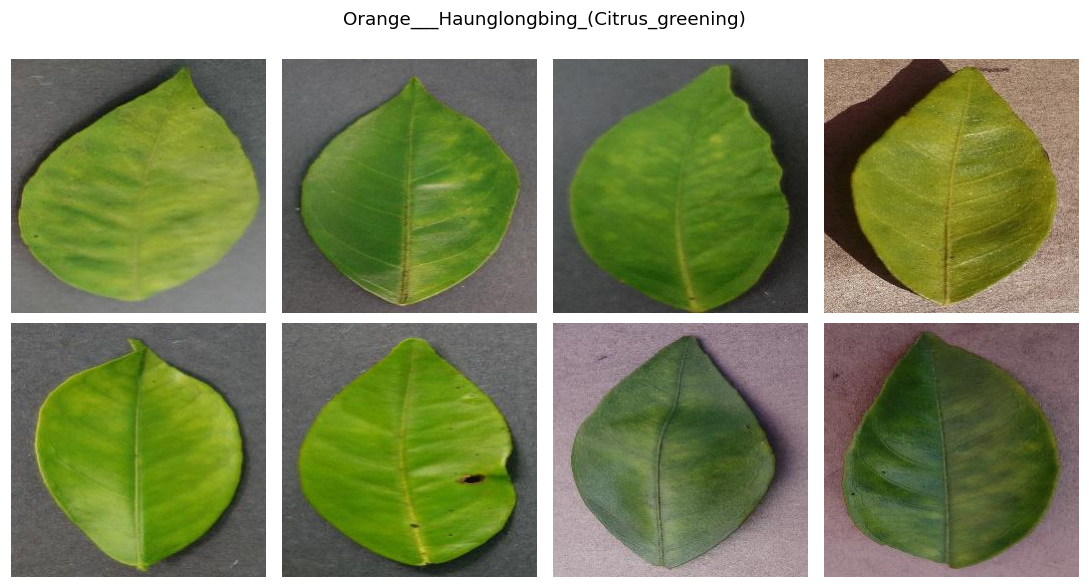

In [10]:
clase = df.index[0]  # clase más numerosa del dataset
cid = [k for k, v in id2name.items() if v == clase][0]
idxs = np.where(labels_train == cid)[0]
rng = np.random.default_rng(42)
sample = rng.choice(idxs, size=8, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(10, 5.5))
for ax, i in zip(axes.ravel(), sample):
    ax.imshow(train[int(i)]["image"])
    ax.axis("off")
fig.suptitle(clase)
plt.tight_layout()
plt.show()

## 5. Tamaño y modo de las imágenes

Se revisa una muestra de 500 imágenes de train. Casi todas (488) miden 256x256 píxeles y el resto (12), 256x192; todas son RGB. Como los modelos reciben entradas cuadradas, las imágenes se redimensionan (a 128x128 en el baseline y a 224x224 en transfer learning); en las pocas que no son cuadradas, esto implica estirar la imagen.

In [11]:
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(train), size=min(500, len(train)), replace=False)

shapes = Counter()
modes = Counter()
for i in sample_idx:
    img = train[int(i)]["image"]
    shapes[img.size] += 1
    modes[img.mode] += 1

print("Tamaños (ancho, alto) más frecuentes:", shapes.most_common(5))
print("Modos de color:", dict(modes))

Tamaños (ancho, alto) más frecuentes: [((256, 256), 488), ((256, 192), 12)]
Modos de color: {'RGB': 500}


## 6. Riesgo de fuga de datos (leakage)

Esta versión del dataset **no trae `leaf_id`**, así que el split no pudo agruparse por hoja física y puede haber fotos casi idénticas de una misma hoja en train y en test. Si eso ocurre, el modelo "ya vio" parte del test y las métricas salen infladas. El problema no se puede eliminar, pero sí **estimar**: se calcula un hash perceptual simple (average hash de 8x8 píxeles) para 8.000 imágenes de train y 1.500 de test, y se cuenta cuántas imágenes de test coinciden exactamente con alguna de las de train. Es una heurística que **subestima** el problema (solo detecta casi-duplicados muy parecidos y se revisa una muestra de train), por lo que el resultado es una **cota inferior**, no el valor real.

In [12]:
def ahash(img, size=8):
    g = img.convert("L").resize((size, size))
    a = np.asarray(g, dtype=np.float32)
    bits = (a > a.mean()).flatten()
    return bits.tobytes()

rng = np.random.default_rng(42)
n_train = min(8000, len(train))
n_test = min(1500, len(test))
idx_tr = rng.choice(len(train), size=n_train, replace=False)
idx_te = rng.choice(len(test), size=n_test, replace=False)

hashes_train = {}
for i in idx_tr:
    hashes_train.setdefault(ahash(train[int(i)]["image"]), []).append(int(i))

hits = sum(ahash(test[int(i)]["image"]) in hashes_train for i in idx_te)
print(f"Imágenes de test con un casi-duplicado en la muestra de train: {hits}/{n_test} ({hits / n_test:.1%})")

Imágenes de test con un casi-duplicado en la muestra de train: 19/1500 (1.3%)


## 7. Conclusiones del EDA

- **Tamaño y splits:** el dataset tiene 55.447 imágenes en 39 clases (38 de cultivo/condición más `Background_without_leaves`). Como no trae `leaf_id`, se usó un split estratificado 70/15/15 (train 38.812, val 8.317, test 8.318) con semilla fija. Las proporciones por clase se mantienen entre los tres conjuntos.
- **Balance de clases:** desbalance de 36,2x entre la clase más grande (`Orange___Haunglongbing_(Citrus_greening)`, 5.507 imágenes) y la más chica (`Potato___healthy`, 152). Por eso la métrica principal será el F1 macro, con métricas por clase, y se comparará entrenar con y sin pesos de clase.
- **Composición:** 39.221 imágenes de hojas enfermas, 15.083 sanas y 1.143 de fondo sin hoja. El fondo se mantiene como clase en el baseline (sirve para rechazar fotos sin hoja) y se reportarán métricas con y sin ella.
- **Imágenes:** RGB, casi todas de 256x256 píxeles (488 de 500 en la muestra; el resto de 256x192). Son hojas individuales fotografiadas en condiciones controladas, con fondo uniforme y poca variación de iluminación (se aprecia en las secciones 4 y 4.1).
- **Riesgo de fuga:** sin `leaf_id` no se pudo agrupar por hoja. Una estimación conservadora con hash perceptual detectó al menos 1,3 % de casi-duplicados entre test y train (19 de 1.500); es un piso, no el valor real, por lo que las métricas pueden ser algo optimistas. Se complementa con una prueba de robustez en imágenes de otras fuentes (notebook 04).
- **Decisiones para el modelado:** imágenes reducidas para poder entrenar en CPU, augmentation básico (flip, rotación leve, zoom), F1 macro como métrica principal, y matriz de confusión y Grad-CAM para analizar los errores.